In [1]:
!pip install torch torchvision psutil matplotlib pandas -q

In [2]:
import torch
import torch.nn as nn
import torchvision.models as models
import time
import psutil
import pandas as pd
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Selected Device:", device)

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
    print("GPU Memory:",
          round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
          "GB")
else:
    print("GPU not available. Running on CPU.")

Selected Device: cuda
GPU Name: Tesla T4
GPU Memory: 14.56 GB


In [4]:
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

model = model.to(device)

model.eval()

print("ResNet18 model loaded successfully!")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 132MB/s]


ResNet18 model loaded successfully!


In [5]:
batch_size = 32

input_data = torch.randn(
    batch_size, 3, 224, 224
)

print("Input shape:", input_data.shape)
print("Sample data created successfully!")

Input shape: torch.Size([32, 3, 224, 224])
Sample data created successfully!


In [6]:
start = time.time()

input_gpu = input_data.to(device)

if device.type == "cuda":
    torch.cuda.synchronize()

transfer_time = time.time() - start

print("Data transfer time:",
      round(transfer_time * 1000, 3), "ms")

Data transfer time: 6.378 ms


In [7]:
with torch.no_grad():

    start = time.time()

    output = model(input_gpu)

    if device.type == "cuda":
        torch.cuda.synchronize()

    inference_time = time.time() - start

print("Inference completed successfully!")
print("Output shape:", output.shape)

print("Inference time:",
      round(inference_time * 1000, 3), "ms")

Inference completed successfully!
Output shape: torch.Size([32, 1000])
Inference time: 1429.473 ms


In [8]:
cpu_model = model.to("cpu")
cpu_input = input_data

with torch.no_grad():

    start = time.time()

    cpu_output = cpu_model(cpu_input)

    cpu_time = time.time() - start

print("CPU Inference Time:",
      round(cpu_time * 1000, 3), "ms")

model = model.to(device)

CPU Inference Time: 2426.852 ms


In [9]:
# Warm-up
with torch.no_grad():
    for _ in range(10):
        model(input_gpu)

if device.type == "cuda":
    torch.cuda.synchronize()

# Measure execution time
times = []

with torch.no_grad():
    for _ in range(50):

        start = time.time()

        output = model(input_gpu)

        if device.type == "cuda":
            torch.cuda.synchronize()

        times.append(time.time() - start)

avg_latency = sum(times) / len(times)

print("Average GPU Latency:",
      round(avg_latency * 1000, 3), "ms")

Average GPU Latency: 26.55 ms


In [10]:
throughput = batch_size / avg_latency

print("Batch Size:", batch_size)
print("Throughput:",
      round(throughput, 2), "images/second")

Batch Size: 32
Throughput: 1205.28 images/second


In [11]:
if device.type == "cuda":

    allocated = torch.cuda.memory_allocated() / 1024**2
    reserved = torch.cuda.memory_reserved() / 1024**2

    print("GPU Allocated Memory:",
          round(allocated, 2), "MB")

    print("GPU Reserved Memory:",
          round(reserved, 2), "MB")

else:
    print("GPU memory information is unavailable.")

GPU Allocated Memory: 72.44 MB
GPU Reserved Memory: 280.0 MB


In [12]:
cpu_usage = psutil.cpu_percent(interval=1)
ram_usage = psutil.virtual_memory().percent

print("CPU Usage:", cpu_usage, "%")
print("RAM Usage:", ram_usage, "%")

CPU Usage: 49.0 %
RAM Usage: 18.9 %


In [13]:
performance = pd.DataFrame({
    "Device": ["CPU", "GPU"],
    "Inference Time (ms)": [
        cpu_time * 1000,
        avg_latency * 1000
    ]
})

print(performance)

  Device  Inference Time (ms)
0    CPU          2426.852226
1    GPU            26.549869


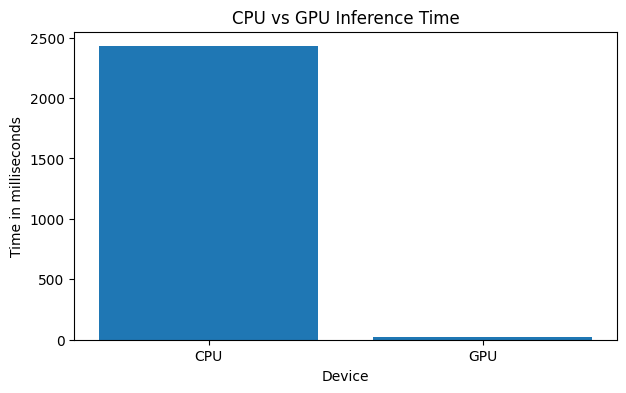

In [14]:
plt.figure(figsize=(7, 4))

plt.bar(
    performance["Device"],
    performance["Inference Time (ms)"]
)

plt.title("CPU vs GPU Inference Time")
plt.xlabel("Device")
plt.ylabel("Time in milliseconds")

plt.show()

In [15]:
print("SYSTEM BOTTLENECK ANALYSIS")

print("---------------------------")

print("CPU Inference Time:",
      round(cpu_time * 1000, 3), "ms")

print("GPU Inference Time:",
      round(avg_latency * 1000, 3), "ms")

print("Data Transfer Time:",
      round(transfer_time * 1000, 3), "ms")

print("CPU Usage:", cpu_usage, "%")

print("RAM Usage:", ram_usage, "%")

if transfer_time > avg_latency:
    print("Possible Bottleneck: Data Transfer")
elif avg_latency > 0:
    print("Possible Bottleneck: Model Computation")

if device.type == "cuda":
    print("GPU Memory Usage:",
          round(torch.cuda.memory_allocated() / 1024**2, 2),
          "MB")

print("Analysis completed!")

SYSTEM BOTTLENECK ANALYSIS
---------------------------
CPU Inference Time: 2426.852 ms
GPU Inference Time: 26.55 ms
Data Transfer Time: 6.378 ms
CPU Usage: 49.0 %
RAM Usage: 18.9 %
Possible Bottleneck: Model Computation
GPU Memory Usage: 72.44 MB
Analysis completed!


In [16]:
batch_sizes = [1, 8, 16, 32]
results = []

for size in batch_sizes:

    sample = torch.randn(
        size, 3, 224, 224
    ).to(device)

    with torch.no_grad():

        # Warm-up
        model(sample)

        if device.type == "cuda":
            torch.cuda.synchronize()

        start = time.time()

        for _ in range(10):
            model(sample)

        if device.type == "cuda":
            torch.cuda.synchronize()

        elapsed = (time.time() - start) / 10

    results.append({
        "Batch Size": size,
        "Latency (ms)": elapsed * 1000,
        "Throughput (images/sec)": size / elapsed
    })

batch_results = pd.DataFrame(results)

print(batch_results)

   Batch Size  Latency (ms)  Throughput (images/sec)
0           1      3.911757               255.639571
1           8     13.190722               606.486871
2          16     14.047050              1139.029153
3          32     26.668429              1199.920683


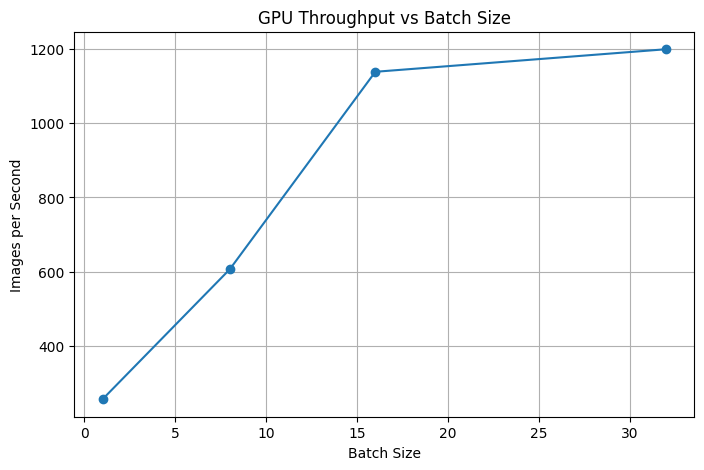

In [17]:
plt.figure(figsize=(8, 5))

plt.plot(
    batch_results["Batch Size"],
    batch_results["Throughput (images/sec)"],
    marker="o"
)

plt.title("GPU Throughput vs Batch Size")
plt.xlabel("Batch Size")
plt.ylabel("Images per Second")

plt.grid(True)
plt.show()

In [18]:
print("EXPERIMENT RESULT")
print("==============================")

print("Model: ResNet18")
print("Device:", device)
print("Batch Size:", batch_size)

print("CPU Time:",
      round(cpu_time * 1000, 3), "ms")

print("GPU Time:",
      round(avg_latency * 1000, 3), "ms")

print("GPU Throughput:",
      round(throughput, 2), "images/sec")

print("Result: GPU inference execution "
      "and system bottleneck analysis completed successfully.")

EXPERIMENT RESULT
Model: ResNet18
Device: cuda
Batch Size: 32
CPU Time: 2426.852 ms
GPU Time: 26.55 ms
GPU Throughput: 1205.28 images/sec
Result: GPU inference execution and system bottleneck analysis completed successfully.
